In [9]:
# Cell 1 — Config
from pathlib import Path
import pandas as pd
import cv2

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CAMERAS = {
    "14_43": {
        "front":      ROOT / "videos_2" / "optimized_14_43_front_cropped.mp4",
        "back_left":  ROOT / "videos_2" / "optimized_14_43_back_left_cropped.mp4",
        "back_right": ROOT / "videos_2" / "optimized_14_43_back_right_cropped.mp4",
    },
    "14_55": {
        "front":      ROOT / "videos_2" / "optimized_14_55_front_cropped.mp4",
        "back_left":  ROOT / "videos_2" / "optimized_14_55_back_left_cropped.mp4",
        "back_right": ROOT / "videos_2" / "optimized_14_55_back_right_cropped.mp4",
    },
}
GT_XLSX = {
    "14_43": (ROOT / "data" / "14_43_ground_truth_ai_app.xlsx", "14_43_ground_truth"),
    "14_55": (ROOT / "data" / "14_55_ground_truth_ai_app.xlsx", "14_55_ground_truth"),
}
VIDEO_START = {
    "14_43": pd.Timestamp("2025-03-26 14:43:00"),
    "14_55": pd.Timestamp("2025-03-26 14:55:00"),
}

OUT_DIR = ROOT / "data" / "ocr_frames"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ROOT / "results" / "cvat_training" / "yolo11n_cvat_all" / "weights" / "best.pt"
CROP_BAND = (0.20, 0.75)   # shoulder region inside the bbox

# Camera reliability weighting — lower = higher priority
CAM_PRIORITY = {"back_right": 0, "front": 1, "back_left": 2}

print("model:", MODEL_PATH.exists(), MODEL_PATH.name)
for vk, cams in CAMERAS.items():
    for cam, p in cams.items():
        print(f"{vk}/{cam:10s}", p.exists(), p.name)
print("gt files:")
for vk, (p, s) in GT_XLSX.items():
    print(" ", vk, p.exists(), p.name, "->", s)
print("output:", OUT_DIR.relative_to(ROOT))

model: True best.pt
14_43/front      True optimized_14_43_front_cropped.mp4
14_43/back_left  True optimized_14_43_back_left_cropped.mp4
14_43/back_right True optimized_14_43_back_right_cropped.mp4
14_55/front      True optimized_14_55_front_cropped.mp4
14_55/back_left  True optimized_14_55_back_left_cropped.mp4
14_55/back_right True optimized_14_55_back_right_cropped.mp4
gt files:
  14_43 True 14_43_ground_truth_ai_app.xlsx -> 14_43_ground_truth
  14_55 True 14_55_ground_truth_ai_app.xlsx -> 14_55_ground_truth
output: data\ocr_frames


In [10]:
# Cell 2 — target list of (video, Sequence, t_sec, gt_tare, gt_year, color)
gt_rows = []
for vk, (xlsx_path, sheet) in GT_XLSX.items():
    df = pd.read_excel(xlsx_path, sheet_name=sheet)
    df["gt_tare"] = pd.to_numeric(df["tarra"], errors="coerce")
    df["gt_year"] = pd.to_numeric(df["year"], errors="coerce")
    df = df.dropna(subset=["gt_tare", "gt_year"]).copy()
    df["gt_year"] = df["gt_year"].astype(int)
    df["t_sec"] = (df["Time"] - VIDEO_START[vk]).dt.total_seconds()
    df = df[df["t_sec"] >= 0].copy()
    if "Sequence" not in df.columns:
        df["Sequence"] = range(len(df))
    df["Sequence"] = df["Sequence"].astype(int)
    df["color"] = df["color"].astype(str).str.strip().str.lower() if "color" in df.columns else "?"
    for _, r in df.iterrows():
        gt_rows.append({
            "video": vk, "Sequence": int(r["Sequence"]),
            "t_sec": float(r["t_sec"]),
            "gt_tare": float(r["gt_tare"]), "gt_year": int(r["gt_year"]),
            "color": r["color"],
        })

gt_targets = pd.DataFrame(gt_rows).sort_values(["video", "t_sec"]).reset_index(drop=True)
print("target bottles:", len(gt_targets))
print(gt_targets.groupby("video").size())
print("colours:", gt_targets.groupby("color").size().to_dict())
gt_targets.head()

target bottles: 186
video
14_43    120
14_55     66
dtype: int64
colours: {'black': 156, 'cyan': 30}


,video,Sequence,t_sec,gt_tare,gt_year,color
0,14_43,542436,39.0,10.8,2033,black
1,14_43,542437,43.0,10.7,2036,black
2,14_43,542439,51.0,10.6,2036,black
3,14_43,542440,54.0,10.6,2036,black
4,14_43,542441,57.0,15.6,2033,black


In [11]:
# Cell 3 — For every GT bottle, grab 1 shoulder crop per camera (3 total)
from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))
print("model classes:", model.names)

def shoulder_crop(frame):
    """Detect bottle in frame, return (crop, box) or (None, None)."""
    res = model.predict(frame, conf=0.25, verbose=False)
    if not res or res[0].boxes is None or len(res[0].boxes) == 0:
        return None, None
    boxes = res[0].boxes.xyxy.cpu().numpy()
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    i = int(areas.argmax())
    x1, y1, x2, y2 = boxes[i].astype(int)
    h = y2 - y1
    crop = frame[y1 + int(h * CROP_BAND[0]): y1 + int(h * CROP_BAND[1]), x1:x2]
    if crop.size == 0:
        return None, None
    return crop, boxes[i]

# Clear old crops from previous runs
for p in OUT_DIR.glob("crop_*.jpg"):
    p.unlink()

# Open one VideoCapture per (session, camera), all kept open at the same time
caps = {vk: {cam: cv2.VideoCapture(str(path)) for cam, path in cams.items()}
        for vk, cams in CAMERAS.items()}

manifest = []
for _, row in gt_targets.iterrows():
    vk, seq, t_sec = row["video"], int(row["Sequence"]), float(row["t_sec"])
    for cam, cap in caps[vk].items():
        cap.set(cv2.CAP_PROP_POS_MSEC, t_sec * 1000.0)
        ok, frame = cap.read()
        if not ok:
            continue
        crop, _box = shoulder_crop(frame)
        if crop is None:
            continue
        out_path = OUT_DIR / f"crop_{vk}_{seq:06d}_{cam}.jpg"
        cv2.imwrite(str(out_path), crop)
        manifest.append({
            "video": vk, "Sequence": seq, "t_sec": t_sec,
            "camera": cam, "priority": CAM_PRIORITY[cam],
            "crop_path": str(out_path.relative_to(ROOT)),
            "gt_tare": row["gt_tare"], "gt_year": row["gt_year"],
            "color": row["color"],
        })

for vk in caps:
    for cap in caps[vk].values():
        cap.release()

manifest_df = pd.DataFrame(manifest)
manifest_path = OUT_DIR / "manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print(f"\ncrops saved: {len(manifest_df)}")
print(f"per video:   {manifest_df.groupby('video').size().to_dict()}")
print(f"per camera:  {manifest_df.groupby('camera').size().to_dict()}")
bottles = manifest_df.groupby(["video", "Sequence"]).size()
print(f"bottles with 1 crop: {(bottles == 1).sum()}")
print(f"bottles with 2 crops: {(bottles == 2).sum()}")
print(f"bottles with 3 crops: {(bottles == 3).sum()}")
print("manifest:", manifest_path.relative_to(ROOT))

model classes: {0: 'gas-bottles'}

crops saved: 524
per video:   {'14_43': 332, '14_55': 192}
per camera:  {'back_left': 179, 'back_right': 179, 'front': 166}
bottles with 1 crop: 2
bottles with 2 crops: 18
bottles with 3 crops: 162
manifest: data\ocr_frames\manifest.csv


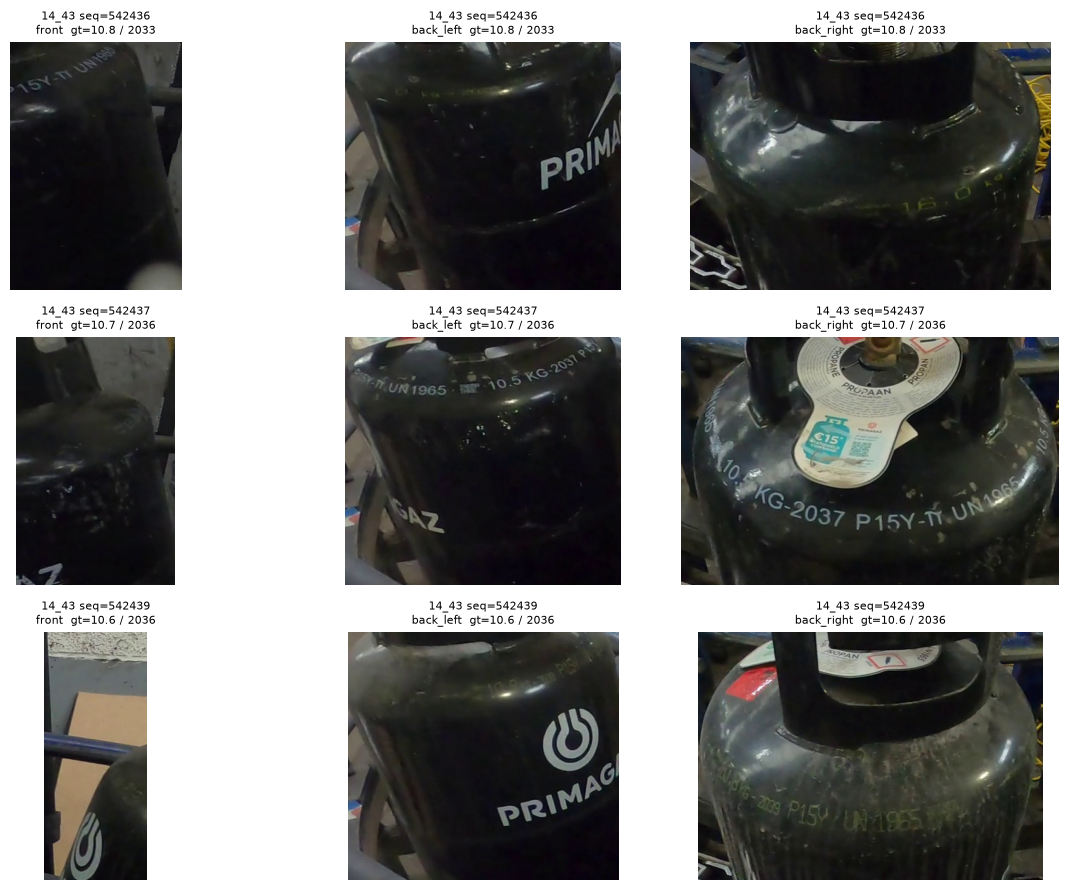

In [12]:
# Cell 4 — preview: 3 bottles × 3 cameras grid
import matplotlib.pyplot as plt

full = manifest_df.groupby(["video", "Sequence"]).size()
trio = full[full == 3].index.tolist()[:3]

fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for row_i, (vk, seq) in enumerate(trio):
    subset = manifest_df[(manifest_df.video == vk) & (manifest_df.Sequence == seq)]
    for col_i, cam in enumerate(["front", "back_left", "back_right"]):
        ax = axes[row_i, col_i]
        r = subset[subset.camera == cam]
        if len(r) == 0:
            ax.axis("off"); continue
        img = cv2.imread(str(ROOT / r.iloc[0].crop_path))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{vk} seq={seq}\n{cam}  gt={r.iloc[0].gt_tare} / {r.iloc[0].gt_year}",
                     fontsize=8)
        ax.axis("off")
plt.tight_layout(); plt.show()

In [13]:
# Cell 5 — summary
print("=== Data preparation summary ===")
print(f"GT bottles with readable tare+year : {len(gt_targets)}")
print(f"crops actually saved              : {len(manifest_df)}")
print(f"per camera                        : {manifest_df.groupby('camera').size().to_dict()}")
print(f"per colour                        : {manifest_df.groupby('color').size().to_dict()}")
print(f"bottles with 3 camera crops       : {(manifest_df.groupby(['video','Sequence']).size() == 3).sum()}")
print(f"crop band                          : {CROP_BAND}")
print(f"camera priority                    : {CAM_PRIORITY}")
print(f"output dir                         : {OUT_DIR.relative_to(ROOT)}")

=== Data preparation summary ===
GT bottles with readable tare+year : 186
crops actually saved              : 524
per camera                        : {'back_left': 179, 'back_right': 179, 'front': 166}
per colour                        : {'black': 443, 'cyan': 81}
bottles with 3 camera crops       : 162
crop band                          : (0.2, 0.75)
camera priority                    : {'back_right': 0, 'front': 1, 'back_left': 2}
output dir                         : data\ocr_frames
